In [1]:
import inspect
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import statsmodels.api as sm

from Regression_utils import *
from PCA_utils import *
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

In [2]:
main_df = pd.read_excel(r"C:\Users\loganfrideley\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data.xlsx")

In [3]:
print(main_df.columns)

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Name', 'Year-Month', 'Hours',
       'Water Total', 'PSI', 'Revenue', 'Metered DM', 'Power Factor',
       'Billed DM', 'Billing KWH', 'Fuel Rate', 'Electrical Bill',
       'Workover Info', 'Workover Cost', 'Pump Model', 'Pump Number',
       'Plunger Size', 'Install Date', 'Maintenance Cost',
       'Maintenance Comments', 'Workover Count', 'Disposal Rate',
       'KWH per Barrel', 'Cost per KWH', 'Electrical Cost per Barrel',
       'Maintenance Cost per Barrel', 'Workover Cost per Barrel',
       'Revenue per Barrel', 'Income per Barrel', 'Income', 'Total Cost',
       'KWH/Water Ratio', 'Pump Age (years)', 'Workover Category',
       'Cumulative Electrical Cost', 'Cumulative Workover Cost',
       'Cumulative Maintenance Cost', 'Cumulative Total Cost',
       'Cumulative Income', 'Cumulative Revenue'],
      dtype='str')


In [4]:
# Double check that there are no problematic values for our data
print(main_df[main_df["PSI"].isna()])
print(np.isinf(main_df["PSI"]).sum())
print(main_df[main_df["Billing KWH"].isna()])
print(main_df["Billing KWH"].isna().sum())
print(np.isinf(main_df["Billing KWH"]).sum())

Empty DataFrame
Columns: [Unnamed: 0.1, Unnamed: 0, Name, Year-Month, Hours, Water Total, PSI, Revenue, Metered DM, Power Factor, Billed DM, Billing KWH, Fuel Rate, Electrical Bill, Workover Info, Workover Cost, Pump Model, Pump Number, Plunger Size, Install Date, Maintenance Cost, Maintenance Comments, Workover Count, Disposal Rate, KWH per Barrel, Cost per KWH, Electrical Cost per Barrel, Maintenance Cost per Barrel, Workover Cost per Barrel, Revenue per Barrel, Income per Barrel, Income, Total Cost, KWH/Water Ratio, Pump Age (years), Workover Category, Cumulative Electrical Cost, Cumulative Workover Cost, Cumulative Maintenance Cost, Cumulative Total Cost, Cumulative Income, Cumulative Revenue]
Index: []

[0 rows x 42 columns]
0
Empty DataFrame
Columns: [Unnamed: 0.1, Unnamed: 0, Name, Year-Month, Hours, Water Total, PSI, Revenue, Metered DM, Power Factor, Billed DM, Billing KWH, Fuel Rate, Electrical Bill, Workover Info, Workover Cost, Pump Model, Pump Number, Plunger Size, Install

<Axes: >

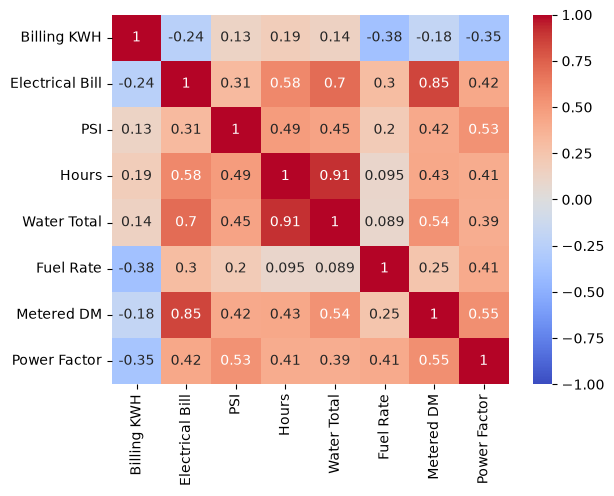

In [5]:
# basic correlation plot
corr_data = main_df[["Billing KWH", "Electrical Bill", "PSI", "Hours", "Water Total", "Fuel Rate", "Metered DM", "Power Factor"]]
corr_matrix = corr_data.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

In [7]:
exogs = ["PSI", "Billing KWH", "Hours", "Water Total", "Fuel Rate", "Metered DM", "Power Factor"]
endogs = ["Electrical Cost per Barrel"]
#endogs = ["Electrical Bill", "Billing KWH", "Water Total", "Metered DM", "Hours"]
os.chdir(r"C:\Users\jroland\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Graphs\Linear")
folder = os.getcwd()
folder = Path(folder)

lm_dict = datamine_ls(endogs, exogs, main_df)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:\\Users\\jroland\\East Texas Salt Water Disposal Company\\Operations - Documents\\Engineering\\Disposal Wells\\Workover Analysis\\Graphs\\Linear'

In [5]:
write_ls_summaries(lm_dict, input_path=os.getcwd())

In [ ]:
# Plot the relationships which can be visualized
# and plot the residuals for all relationships.
for label, lm in lm_dict.items():
    plot_ls(lm, os.getcwd())

In [10]:
#Loading Derived ALl Data with PCA scores excel sheet
#I am going to be testing the standardized data and comparing it to the PCA scores.
testing_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data with PCA Scores.xlsx")
testing_df

,Unnamed: 0.2,Hours,Water Total,PSI,Revenue,Disposal Rate,Metered DM,Billed DM,Power Factor,Billing KWH,...,Total Cost,KWH/Water Ratio,Pump Age (years),Workover Category,Cumulative Electrical Cost,Cumulative Workover Cost,Cumulative Maintenance Cost,Cumulative Total Cost,Cumulative Income,Cumulative Revenue
0,0,1.074277,1.072005,0.291287,0.218749,0.305695,0.238438,0.320388,0.536842,-0.190361,...,5973.24,0.248452,NaN,NaN,5973.24,0.00,0.00,5973.24,12592.976116,18566.216116
1,1,1.147690,1.144037,0.305786,0.364694,0.305695,0.238438,0.320388,0.592328,-0.190361,...,6133.69,0.249470,NaN,NaN,12106.93,0.00,0.00,12106.93,26779.437740,38886.367740
2,2,1.192245,1.187755,0.325118,0.377172,0.329402,0.234942,0.345659,0.839396,-0.190361,...,6864.32,0.280947,NaN,NaN,18971.25,0.00,0.00,18971.25,40385.229337,59356.479337
3,3,1.074577,1.072299,0.296120,0.348066,0.337305,0.224454,0.361210,0.592328,-0.173020,...,6183.91,0.256835,NaN,NaN,25155.16,0.00,0.00,25155.16,54321.647801,79476.807801
4,4,0.937039,0.937346,0.292898,0.266334,0.281987,0.217463,0.309696,0.561968,-0.173020,...,6062.69,0.267065,NaN,NaN,31217.85,0.00,0.00,31217.85,67397.036841,98614.886841
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9391,9391,-1.401729,-1.357450,-2.323369,-1.326140,-1.613613,-1.736673,-1.607029,-1.101033,-2.429270,...,932.66,0.000000,NaN,NaN,203746.50,101898.61,13771.57,319416.68,92012.238184,411428.918184
9392,9392,-1.401729,-1.357450,-2.323369,-1.326140,-1.614600,-1.998856,-1.607029,-1.101033,-2.429270,...,932.66,0.000000,NaN,NaN,204679.16,101898.61,13771.57,320349.34,91079.578184,411428.918184
9393,9393,-1.401729,-1.357450,-2.323369,-1.326140,-1.614600,-1.998856,-1.607029,-1.101033,0.663098,...,933.89,0.000000,NaN,NaN,205613.05,101898.61,13771.57,321283.23,90145.688184,411428.918184
9394,9394,-1.401729,-1.357450,-2.323369,0.119009,-1.614600,-1.998856,-1.607029,-1.101033,0.663098,...,933.89,0.000000,NaN,NaN,206546.94,101898.61,13771.57,322217.12,NaN,NaN


In [31]:
# Standard Linear Regression
# PREDICTIVE
# Exploration of KWH and billing relationships
# Variables of interest: Predictors: Hours, Water Total, PSI, Metered DM, Power Factor, Billed DM, Fuel Rate
#                        Predicted: Billing KWH

#standard predictors ["Billing, KWH, Fuel Rate, Metered DM"]
#PCR predictors [PC1, PC2, PC3]
predictors = ["Billing KWH", "Fuel Rate", "Metered DM"]
predicted = ["Electrical Bill"]

#dropping

# We need to split dataset based on time, rather than randomly. The last observation for the data is September 2025.
# Let's attempt to predict 6 months worth of data, so the training set will be start -> March 2025
train_X = testing_df[testing_df["Year-Month"] < "2026-02"]
train_X = train_X[predictors]

test_X = testing_df[testing_df["Year-Month"] >= "2026-02"]
test_X = test_X[predictors]

train_y = testing_df[testing_df["Year-Month"] < "2026-02"]
train_y = train_y[predicted]

test_y = testing_df[testing_df["Year-Month"] >= "2026-02"]
test_y = test_y[predicted]

model = LinearRegression()
model.fit(train_X, train_y)

print("Intercept: ", model.intercept_)
print("Coefficients: ", model.coef_)

test_predict = model.predict(test_X)
regressionSummary(test_y, test_predict, test_X)
# Normalization - NOTE: We are explaining rather than predicting in this case, so normalization should transform
#                       all data and not just the training data whose values are applied to the test data.
# NOTE: Normalization applies to PCA and other methods sensitive to absolute magnitude differences. 
#       OLS linear regression is not one of those.

Intercept:  [0.0032372]
Coefficients:  [[-0.12036645  0.39690732  0.33578036]]
('Mean Error (ME): ', array([-0.05826952]))
('Root Mean Squared Error (RMSE): ', 0.6541603004621467)
('Mean Absolute Error (MAE): ', array([0.48297336]))
('Mean Percent Error (MPE): ', array([50.10031731]))
('Mean Absolute Percent Error (MAPE): ', array([103.67768479]))
('R squared : ', np.float64(0.4857750881810775))
('Adjusted R squared: ', np.float64(0.48279695162614167))





In [ ]:
#Standard One Month
Intercept:  [0.00039747]
Coefficients:  [[-0.11361605  0.40164511  0.33863563]]
('Mean Error (ME): ', array([-0.04292678]))
('Root Mean Squared Error (RMSE): ', 0.6332394807649228)
('Mean Absolute Error (MAE): ', array([0.47003162]))
('Mean Percent Error (MPE): ', array([45.32296784]))
('Mean Absolute Percent Error (MAPE): ', array([114.32104336]))
('R squared : ', np.float64(0.49248658237692344))
('Adjusted R squared: ', np.float64(0.47414272390861945))

#Standard three month
Intercept:  [0.0008747]
Coefficients:  [[-0.11461733  0.40092322  0.33631768]]
('Mean Error (ME): ', array([-0.03148919]))
('Root Mean Squared Error (RMSE): ', 0.6439588192110697)
('Mean Absolute Error (MAE): ', array([0.47693976]))
('Mean Percent Error (MPE): ', array([52.85210638]))
('Mean Absolute Percent Error (MAPE): ', array([106.10299929]))
('R squared : ', np.float64(0.5145730687253887))
('Adjusted R squared: ', np.float64(0.5089066064926111))

#Standard six month
Intercept:  [0.0032372]
Coefficients:  [[-0.12036645  0.39690732  0.33578036]]
('Mean Error (ME): ', array([-0.05826952]))
('Root Mean Squared Error (RMSE): ', 0.6541603004621467)
('Mean Absolute Error (MAE): ', array([0.48297336]))
('Mean Percent Error (MPE): ', array([50.10031731]))
('Mean Absolute Percent Error (MAPE): ', array([103.67768479]))
('R squared : ', np.float64(0.4857750881810775))
('Adjusted R squared: ', np.float64(0.48279695162614167))

#---------------------------------------------------------------------------------------------
#PCR one month
Intercept:  [0.00125436]
Coefficients:  [[ 0.29518162 -0.07123095  0.31673281]]
('Mean Error (ME): ', array([-0.13547099]))
('Root Mean Squared Error (RMSE): ', 0.45696654467511827)
('Mean Absolute Error (MAE): ', array([0.35373192]))
('Mean Percent Error (MPE): ', array([-17.72251931]))
('Mean Absolute Percent Error (MAPE): ', array([122.69391209]))
('R squared : ', np.float64(0.7357102184936488))
('Adjusted R squared: ', np.float64(0.7261575757886001))

#PCR three month
Intercept:  [0.00378221]
Coefficients:  [[ 0.29445765 -0.07173169  0.31807285]]
('Mean Error (ME): ', array([-0.13615942]))
('Root Mean Squared Error (RMSE): ', 0.4578764557381978)
('Mean Absolute Error (MAE): ', array([0.34759393]))
('Mean Percent Error (MPE): ', array([-23.56514084]))
('Mean Absolute Percent Error (MAPE): ', array([116.35403332]))
('R squared : ', np.float64(0.7545831930810873))
('Adjusted R squared: ', np.float64(0.7517184054516837))

#PCR six month
Intercept:  [-0.00015747]
Coefficients:  [[ 0.29381644 -0.06883867  0.32120506]]
('Mean Error (ME): ', array([0.00283438]))
('Root Mean Squared Error (RMSE): ', 0.4419659192124741)
('Mean Absolute Error (MAE): ', array([0.33971386]))
('Mean Percent Error (MPE): ', array([9.34468792]))
('Mean Absolute Percent Error (MAPE): ', array([113.26854278]))
('R squared : ', np.float64(0.7652734007167283))
('Adjusted R squared: ', np.float64(0.7639139802575589))








Total NaN values replaced with the Median: 891
Total out_df rows: 9396


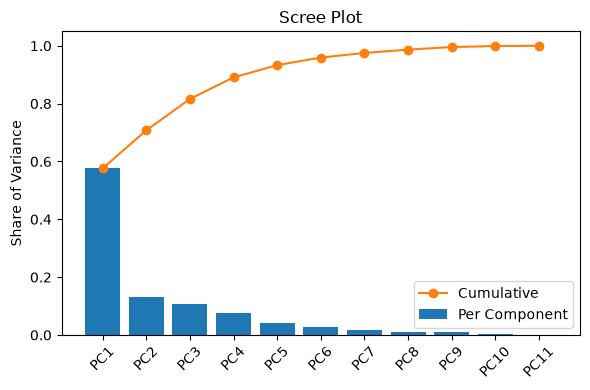

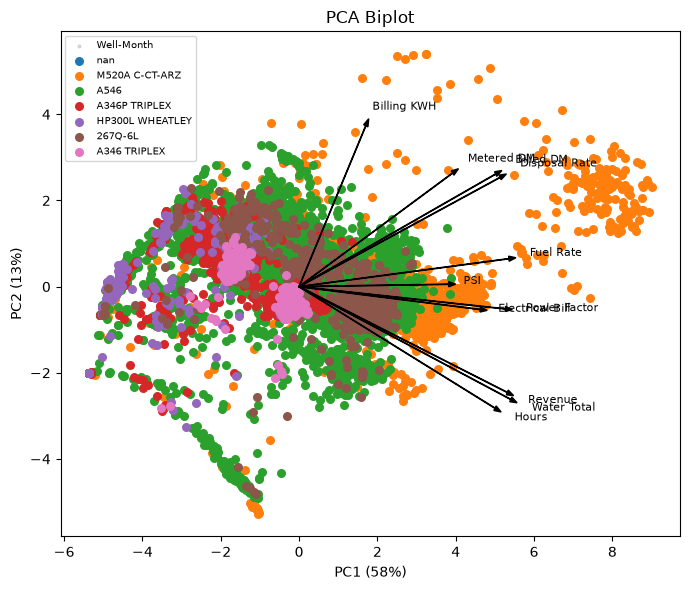

In [4]:
# Principle Components Analysis

# variables used to build principal components
pca_vars = [
    "Hours", "Water Total", "PSI", "Revenue", "Disposal Rate",
    "Metered DM", "Billed DM", "Power Factor", "Billing KWH",
    "Fuel Rate", "Electrical Bill",
]

# variables to compare PCs to later
non_pca_vars = ["Workover Cost", "Maintenance Cost", "Workover Count",
                "Plunger Size", "Pump Age (yrs)"]

# Clean data - use clean_attributes rather than filter_extremes() because we want to 
# preserve dates where workovers happened.
# calculate_valid_ranges returns a dict of valid ranges for the columns passed to it
valid_ranges = calculate_valid_ranges(main_df[pca_vars])

# clean_attributes will skip over attributes not contained in the valid_ranges dict
cleaned_df = clean_attributes(main_df, valid_ranges)

# Scale data
scaler = StandardScaler()

# scaler.fit_transform() returns a numpy array-like, and does not preserve column names
# so columns= needs to be passed into the DataFrame constructor
scaled_df = pd.DataFrame(scaler.fit_transform(cleaned_df), columns=pca_vars, index=cleaned_df.index)

# Run PCA - dict contains pca scores, variance dataframe, loadings dataframe, and scores dataframe
non_pca_cols = [col for col in main_df.columns if col not in pca_vars]
scaled_df = pd.concat([scaled_df, main_df[non_pca_cols]], 
                      axis=1)

os.chdir(r"C:\Users\loganfrideley\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis")
folder = Path(os.getcwd())

# Run PCA - dict contains pca scores, variance dataframe, loadings dataframe, and scores dataframe
pca_dict = run_pca(scaled_df[pca_vars])

out_df = pd.concat([pca_dict["output"], main_df[non_pca_cols]], axis=1)

# write original df concatenated with scores to file
out_df.to_excel("Derived All Data with PCA Scores.xlsx")

variance_df = pca_dict["variance"]
loadings_df = pca_dict["loadings"]
variance_df.to_excel("PCA Variances.xlsx")
loadings_df.to_excel("PCA Loadings.xlsx")

# create scree plot 
plot_scree(pca_dict["variance"], input_path=folder)

# plot biplot
plot_biplot(pca_dict, main_df["Pump Model"], input_path=folder)


In [5]:
datamine_pca(main_df, pca_vars, k_start=1, k_stop=20, 
             out_dir=r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\PCA Mining")  # <-- your directory here

Total NaN values replaced with the Median: 4814
Total out_df rows: 9396
Total NaN values replaced with the Median: 3069
Total out_df rows: 9396
Total NaN values replaced with the Median: 2917
Total out_df rows: 9396


PermissionError: [Errno 13] Permission denied: 'C:\\Users\\LoganFrideley\\East Texas Salt Water Disposal Company\\Operations - Documents\\Engineering\\Disposal Wells\\Workover Analysis\\PCA Mining\\PCA Loadings K=3.xlsx'

In [8]:
count_nas_series = main_df.isna().sum(axis=1)
count = 0
for row in count_nas_series:
    if row > 0:
        count = count + 1
print(count)

9386
